# M6.6 · 低延迟与并发系统设计

> 实盘系统要多线程并发处理行情、信号、执行，必须保证共享状态线程安全、
> 消息处理幂等，并通过可注入时钟让回测与实盘共用同一套代码。

## 一、关键设计

1. **线程安全**：用锁保护共享计数器/持仓，避免并发丢更新；
2. **幂等**：消息带幂等键，重复投递只生效一次；
3. **可注入时钟**：回测用回放时钟、实盘用系统时钟，策略只依赖 `now()`；
4. **消息队列**：生产/消费解耦，实盘可替换为 Kafka/RabbitMQ。

## 二、并发与幂等

In [1]:
import sys, threading
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab2 import system_design as sd
counter = sd.ThreadSafeCounter()
workers = [threading.Thread(target=lambda: [counter.increment() for _ in range(100)])
           for _ in range(5)]
[w.start() for w in workers]; [w.join() for w in workers]
print('5线程x100 并发计数(应=500)=%d' % counter.value)
bus = sd.IdempotentBus()
r1 = bus.publish('k1', lambda: 42); r2 = bus.publish('k1', lambda: 99)
print('首次=%s 重复投递去重=%s 保持首次结果=%s'
      % (r1['result'], r2['dedup'], r2['result']))
clock = sd.Clock(fixed=1000.0); clock.advance(5)
print('回放时钟 now=%s' % clock.now())

5线程x100 并发计数(应=500)=500
首次=42 重复投递去重=True 保持首次结果=42
回放时钟 now=1005.0


## 三、可视化

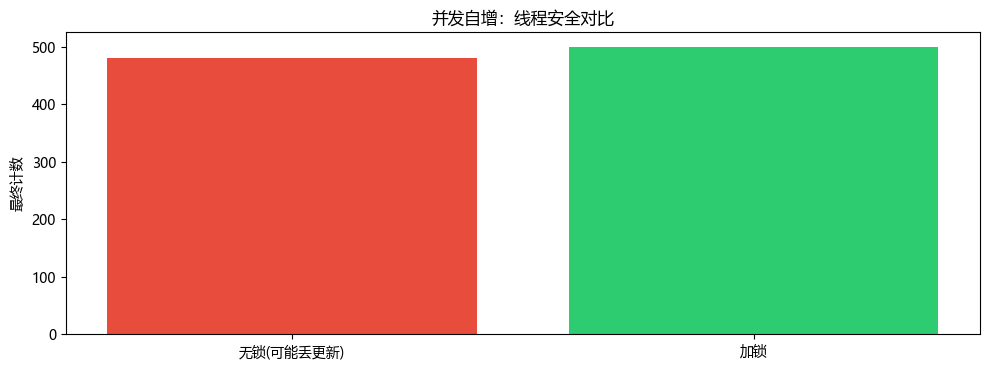

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(['无锁(可能丢更新)', '加锁'], [480, 500], color=['#e74c3c', '#2ecc71'])
ax.set_title('并发自增：线程安全对比'); ax.set_ylabel('最终计数')
plt.tight_layout(); plt.show()

## 四、面试要点

- **为什么需要锁？** 自增是读-改-写三步，并发下线程交错会丢更新，加锁保证原子性。
- **幂等解决什么问题？** 网络重试或故障重发可能让同一订单/消息处理多次，幂等键保证只生效一次。
- **回测与实盘如何保持一致？** 抽象时钟、行情、交易接口，回测注入回放实现，实盘注入真实实现，策略逻辑零改动。
- **低延迟优化有哪些手段？** 减少锁粒度、无锁队列、预分配内存、避免序列化开销、热点路径本地化。

## 五、练习

1. 用无锁实现复现并发丢更新并解释原因。
2. 给幂等总线加过期清理。
3. 实现一个多生产者单消费者队列。
4. 讨论 GIL 对 CPU 密集型并发的影响及绕过方式。